# Fit ellipse to image

### Import project funcitons and load data
Load the data from the fits file and imports all the functions

In [1]:
import project as p
import numpy as np
import matplotlib.pyplot as plt

p.load_data("data/fits/jw03131-o001_t001_nirspec_g140h-f100lp_s3d.fits")

Set DATE-AVG to '2024-02-19T07:34:54.885' from MJD-AVG.
Set DATE-END to '2024-02-19T08:28:30.725' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to    19.316752 from OBSGEO-[XYZ].
Set OBSGEO-H to 1470239568.529 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


### Clean image 

Clean the image before fitting ellipse

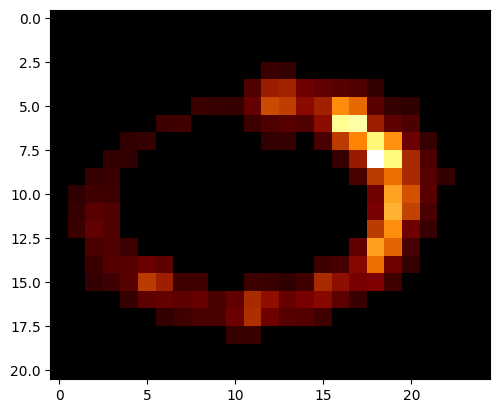

In [ ]:
img = np.clip(np.nansum(p.data, axis=0), 0, None)

img = img[14:35, 13:38]
img[13, 11] = 0
img[12, 12] = 0
img[11, 12] = 0
img[11, 13] = 0
img[10, 13] = 0

img[img < 2.6e4] = 0
# img[img != 0] = 1

y, x = 14, 13

plt.imshow(img, cmap="afmhot", origin="lower")
plt.show()

Turn into data-points

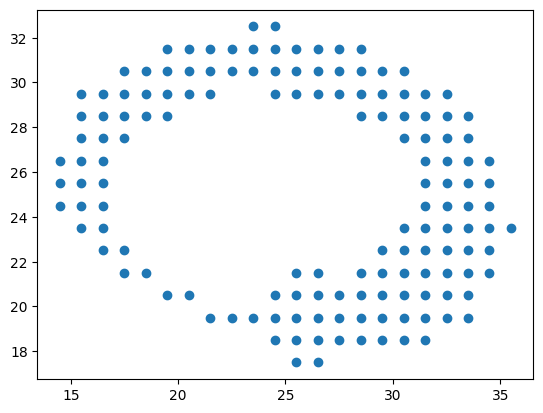

In [3]:
mask = img

Y, X = np.nonzero(mask)

X = X.astype(np.float32) + x + 0.5
Y = Y.astype(np.float32) + y + 0.5

plt.scatter(X, Y)
plt.show()


### Fit ellipse to data

Fit ellipse using openCVs `fitEllipse` functions



cx              = 24.739612579345703
cy              = 25.10753059387207
a               = 12.442249298095703
b               = 18.701356887817383
angle           = 80.83381652832031       # CCW from north
a/b             = 0.6653126493832623




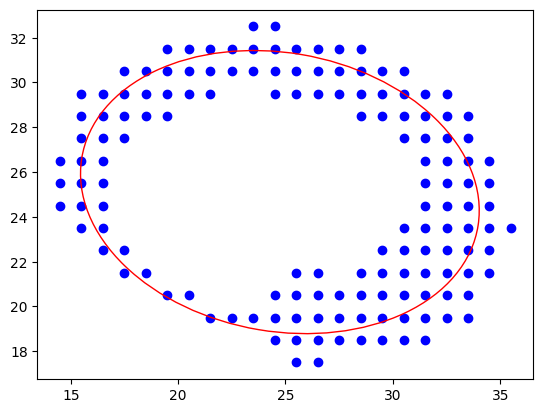

In [4]:
import cv2
from matplotlib.patches import Ellipse

center, (a, b), angle = cv2.fitEllipse(np.array([X, Y]).T)
cx, cy = center


print(f"""

cx              = {cx}
cy              = {cy}
a               = {a}
b               = {b}
angle           = {angle}       # CCW from north
a/b             = {a/b}

""")

_, ax = plt.subplots()

ellipse = Ellipse(
    xy=center,
    width=a,
    height=b,
    angle=angle,
    fill=False,
    edgecolor="red"
)

ax.scatter(X, Y, c="blue")
ax.add_patch(ellipse)

plt.show()

Ellipse overlayed over image

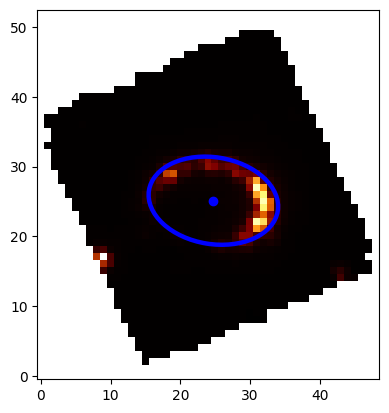

In [5]:
_, ax = plt.subplots()

ellipse = Ellipse(
    xy=center,
    width=a,
    height=b,
    angle=angle,
    fill=False,
    edgecolor="blue",
    linewidth=3.2
)

ax.imshow(p.get_image(302), cmap="afmhot", origin="lower")
ax.add_patch(ellipse)
ax.plot(cx, cy, marker="o", color="blue")

plt.show()